<a href="https://colab.research.google.com/github/DilemmaFixer3/MZKN_labs/blob/main/%D0%9B%D0%A04_%D0%92%D0%B0%D1%80%D1%96%D0%B0%D0%BD%D1%821.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Прогнозування для стратегії розвитку
**Варіант 1.** Задача 1: місто з населенням **220 тис.**, початкові інвестиції **250 тис. грн**, працівників **1–5**, **Львівська** область.
Задача 2: магазин успішний, якщо строк окупності ≤ **N = 3 роки**.
Задача 3 (додаткова): зразок — вага 250 г, діаметр 4 см, колір білий, товщина 3, матеріал дерево.

Файли `stores.csv` і `DataTypes.xlsx` мають бути завантажені.

In [1]:
# === Імпорт бібліотек ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeRegressor, DecisionTreeClassifier,
                          plot_tree, export_text)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import make_column_transformer
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (8, 4)
RS = 42                      # фіксуємо випадковість для відтворюваності

## 0. Завантаження та аудит даних (повторення ЛР №1)

In [2]:
df_raw = pd.read_csv("stores.csv")
print("Розмір:", df_raw.shape)
df_raw.info()

Розмір: (80, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   store_id      80 non-null     object 
 1   region        80 non-null     object 
 2   city          80 non-null     object 
 3   population    80 non-null     float64
 4   format        80 non-null     object 
 5   open_year     80 non-null     int64  
 6   investment    80 non-null     int64  
 7   employees     80 non-null     int64  
 8   area          80 non-null     int64  
 9   rent          80 non-null     float64
 10  revenue       80 non-null     float64
 11  avg_check     77 non-null     float64
 12  profit        80 non-null     float64
 13  online_share  77 non-null     float64
 14  rating        76 non-null     float64
dtypes: float64(7), int64(4), object(4)
memory usage: 9.5+ KB


In [3]:
# --- Пропуски ---
na = df_raw.isna().sum()
print("Пропуски по стовпцях:\n", na[na > 0], sep="")

# --- Підозрілі значення (логічні перевірки з ЛР №1) ---
checks = {
    "area <= 0 (площа не може бути нульовою)":        df_raw["area"] <= 0,
    "open_year > 2026 (рік відкриття в майбутньому)": df_raw["open_year"] > 2026,
    "profit > revenue (прибуток більший за виручку)":  df_raw["profit"] > df_raw["revenue"],
    "profit < 0 при виручці вище медіани":            (df_raw["profit"] < 0) &
                                                       (df_raw["revenue"] > df_raw["revenue"].median()),
}
for name, mask in checks.items():
    print(f"\n{name}: {mask.sum()} запис(ів)")
    if mask.any():
        print(df_raw.loc[mask, ["store_id", "city", "format", "open_year", "area",
                                "revenue", "profit", "investment"]].to_string(index=False))

Пропуски по стовпцях:
avg_check       3
online_share    3
rating          4
dtype: int64

area <= 0 (площа не може бути нульовою): 1 запис(ів)
store_id      city format  open_year  area  revenue  profit  investment
     M42 Кременець     ТЦ       2020     0   1527.0   109.0         334

open_year > 2026 (рік відкриття в майбутньому): 1 запис(ів)
store_id  city format  open_year  area  revenue  profit  investment
     M58 Дубно вулиця       2031    89    936.0   137.0         372

profit > revenue (прибуток більший за виручку): 0 запис(ів)

profit < 0 при виручці вище медіани: 1 запис(ів)
store_id  city format  open_year  area  revenue  profit  investment
     M64 Вараш вулиця       2018    85   2400.0  -180.0         496


**Рішення щодо підозрілих записів:**

| Запис | Проблема | Рішення | Обґрунтування |
|---|---|---|---|
| M64 (Вараш, вулиця) | прибуток −180 тис. грн при **найбільшій** у мережі виручці 2400 тис. грн | **виключити** з навчання | це цільова змінна; вулична точка з 5 працівниками та орендою 184 тис. не може мати максимальну виручку і водночас збиток — імовірна помилка введення. Один такий запис зсуває коефіцієнти МНК (квадратична функція втрат) |
| M58 (Дубно) | рік відкриття 2031 | залишити, `open_year` → NaN | рік не входить в ознаки моделей; решта полів правдоподібні |
| M42 (Кременець, ТЦ) | площа 0 м² при оренді 1158 тис. грн | залишити, `area` → NaN | площа не використовується як ознака; прибуток та інвестиції правдоподібні |
| пропуски `avg_check`, `online_share`, `rating` (10 значень) | NaN | не заповнювати | ці стовпці не використовуються в моделях (вони відомі лише після відкриття магазину) |

In [4]:
df = df_raw.copy()
df.loc[df["open_year"] > 2026, "open_year"] = np.nan   # M58
df.loc[df["area"] <= 0, "area"] = np.nan               # M42
df = df[df["store_id"] != "M64"].reset_index(drop=True)  # M64 — помилковий прибуток
print("Після очищення:", df.shape)
df[["population", "investment", "employees", "profit"]].describe().round(1)

Після очищення: (79, 15)


,population,investment,employees,profit
count,79.0,79.0,79.0,79.0
mean,79.2,495.6,3.7,133.5
std,105.6,166.8,1.3,46.8
min,13.2,250.0,2.0,42.0
25%,23.8,365.5,2.5,100.0
50%,37.2,437.0,4.0,129.0
75%,73.0,655.0,5.0,163.0
max,729.1,796.0,6.0,260.0


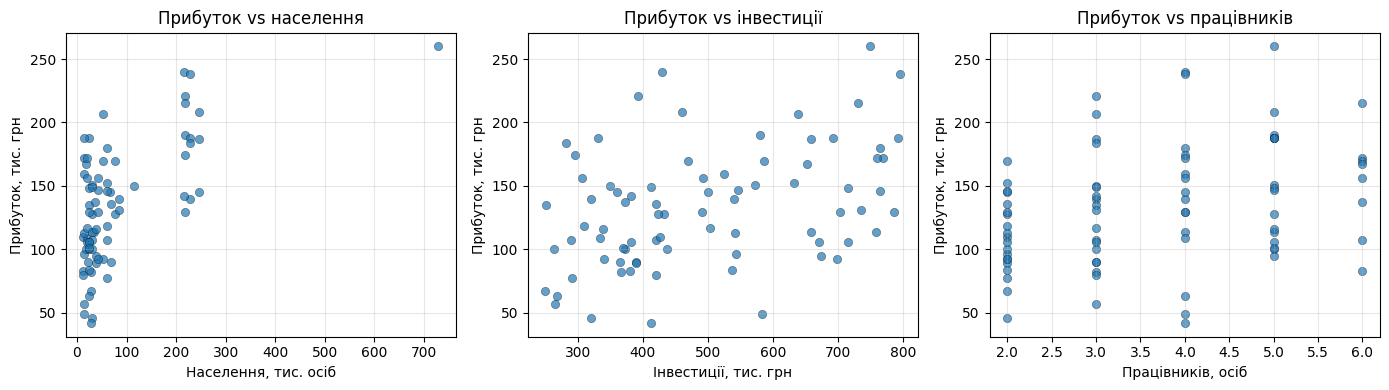

            population  investment  employees  profit
population        1.00        0.12       0.11    0.62
investment        0.12        1.00       0.17    0.40
employees         0.11        0.17       1.00    0.33
profit            0.62        0.40       0.33    1.00


In [5]:
# Як прибуток пов'язаний з ознаками (діаграми розсіювання)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, lab in zip(ax, ["population", "investment", "employees"],
                       ["Населення, тис. осіб", "Інвестиції, тис. грн", "Працівників, осіб"]):
    a.scatter(df[col], df["profit"], alpha=0.7, edgecolor="k", linewidth=0.3)
    a.set_xlabel(lab); a.set_ylabel("Прибуток, тис. грн")
    a.set_title(f"Прибуток vs {lab.split(',')[0].lower()}")
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(df[["population", "investment", "employees", "profit"]].corr().round(2))

Зв'язок прибутку з населенням **нелінійний**: від 13 до ~200 тис. прибуток помітно зростає, далі — насичується
(Львів, 729 тис., дає 260 тис. грн, лише трохи більше, ніж міста на 220 тис.). Тому крім звичайної лінійної регресії
перевіримо варіант з ознакою **log(population)**.

## Задача 1. Регресія: де відкривати нові магазини
### 1а. Лінійна регресія прибутку від населення, інвестицій і кількості працівників

In [6]:
FEATS = ["population", "investment", "employees"]
X = df[FEATS]
y = df["profit"]

# 70 % — навчання, 30 % — тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RS)
print("Навчальна:", X_train.shape, " Тестова:", X_test.shape)

lr = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Коефіцієнти:", dict(zip(FEATS, lr.coef_.round(3))), " b0 =", round(lr.intercept_, 1))
print("MAE :", round(mean_absolute_error(y_test, y_pred_lr), 1))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 1))
print("R2  :", round(r2_score(y_test, y_pred_lr), 3))

Навчальна: (55, 3)  Тестова: (24, 3)
Коефіцієнти: {'population': np.float64(0.359), 'investment': np.float64(0.101), 'employees': np.float64(10.366)}  b0 = 15.7
MAE : 26.4
RMSE: 39.2
R2  : 0.214


In [7]:
# 5-кратна крос-валідація на всій очищеній вибірці
cv5 = KFold(n_splits=5, shuffle=True, random_state=RS)
REG_SCORING = {"MAE": "neg_mean_absolute_error",
               "RMSE": "neg_root_mean_squared_error",
               "R2": "r2"}
s = cross_validate(LinearRegression(), X, y, cv=cv5, scoring=REG_SCORING)
print("MAE по фолдах:", (-s["test_MAE"]).round(1), " середнє:", round(-s["test_MAE"].mean(), 1))
print("RMSE середнє:", round(-s["test_RMSE"].mean(), 1), " R2 середнє:", round(s["test_R2"].mean(), 3))

MAE по фолдах: [30.6 19.5 31.  28.2 32.1]  середнє: 28.3
RMSE середнє: 35.6  R2 середнє: 0.356


**Інтерпретація коефіцієнтів:** кожні додаткові 100 тис. жителів дають у середньому
~+36 тис. грн прибутку на рік, кожні додаткові 100 тис. грн інвестицій — ~+10 тис. грн,
кожен додатковий працівник — ~+10 тис. грн (за незмінних інших ознак).

### 1б. Порівняння: лінійна регресія, дерево рішень, k-NN (+ лінійна з log(population))
Гіперпараметри дерева та k-NN підбираємо `GridSearchCV` лише на навчальній вибірці.

In [8]:
# Лінійна регресія з логарифмом населення (враховує насичення)
def log_pop(Z):
    Z = np.asarray(Z, dtype=float).copy()
    Z[:, 0] = np.log(Z[:, 0])          # перший стовпець — population
    return Z

lr_log = make_pipeline(FunctionTransformer(log_pop), LinearRegression())

# Дерево рішень: підбір глибини і мінімального розміру листка
grid_tree = GridSearchCV(DecisionTreeRegressor(random_state=RS),
                         {"max_depth": range(1, 7), "min_samples_leaf": [1, 3, 5]},
                         cv=cv5, scoring="neg_mean_absolute_error").fit(X_train, y_train)
# k-NN: обов'язкове масштабування; перебір k = 1..15
grid_knn = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()),
                        {"kneighborsregressor__n_neighbors": range(1, 16),
                         "kneighborsregressor__weights": ["uniform", "distance"]},
                        cv=cv5, scoring="neg_mean_absolute_error").fit(X_train, y_train)
print("Дерево:", grid_tree.best_params_)
print("k-NN  :", grid_knn.best_params_)

reg_models = {
    "Лінійна регресія":              LinearRegression(),
    "Лінійна регресія, log(насел.)": lr_log,
    "Дерево рішень":                 grid_tree.best_estimator_,
    "k-NN":                          grid_knn.best_estimator_,
}

rows, preds = [], {}
for name, m in reg_models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[name] = p
    cvr = cross_validate(m, X, y, cv=cv5, scoring=REG_SCORING)
    rows.append({"Модель": name,
                 "MAE тест": mean_absolute_error(y_test, p),
                 "RMSE тест": np.sqrt(mean_squared_error(y_test, p)),
                 "R2 тест": r2_score(y_test, p),
                 "MAE CV": -cvr["test_MAE"].mean(),
                 "RMSE CV": -cvr["test_RMSE"].mean(),
                 "R2 CV": cvr["test_R2"].mean(),
                 "R2 CV std": cvr["test_R2"].std()})
reg_table = pd.DataFrame(rows).set_index("Модель").round(3)
reg_table

Дерево: {'max_depth': 1, 'min_samples_leaf': 1}
k-NN  : {'kneighborsregressor__n_neighbors': 11, 'kneighborsregressor__weights': 'distance'}


,MAE тест,RMSE тест,R2 тест,MAE CV,RMSE CV,R2 CV,R2 CV std
Модель,,,,,,,
Лінійна регресія,26.355,39.171,0.214,28.291,35.586,0.356,0.154
"Лінійна регресія, log(насел.)",20.968,26.902,0.629,25.468,30.947,0.496,0.199
Дерево рішень,33.396,42.494,0.075,34.987,41.656,0.104,0.279
k-NN,24.124,30.296,0.530,29.193,36.403,0.309,0.194


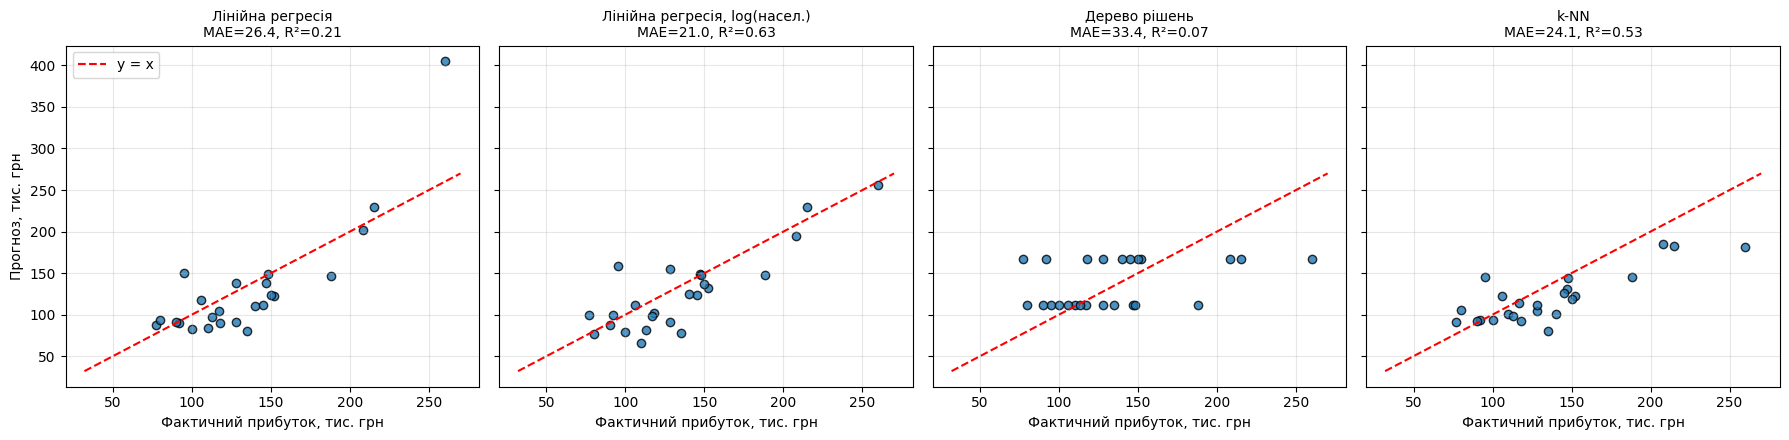

In [9]:
# Діаграми «фактичне – прогнозоване» для всіх моделей
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5), sharex=True, sharey=True)
lo, hi = y.min() - 10, y.max() + 10
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(y_test, p, edgecolor="k", alpha=0.8)
    a.plot([lo, hi], [lo, hi], "r--", label="y = x")
    a.set_title(f"{name}\nMAE={reg_table.loc[name,'MAE тест']:.1f}, R²={reg_table.loc[name,'R2 тест']:.2f}",
                fontsize=10)
    a.set_xlabel("Фактичний прибуток, тис. грн"); a.grid(alpha=0.3)
ax[0].set_ylabel("Прогноз, тис. грн"); ax[0].legend()
plt.tight_layout(); plt.show()

In [10]:
# Вибір кращої моделі — за середнім MAE на крос-валідації (надійніше за одну тестову вибірку з 24 магазинів)
best_name = reg_table["MAE CV"].idxmin()
best_reg = reg_models[best_name].fit(X, y)        # перенавчаємо на всіх 79 магазинах
lin_full = LinearRegression().fit(X, y)
coef = best_reg[-1].coef_; b0 = best_reg[-1].intercept_
print("Краща модель:", best_name)
print(f"profit = {b0:.1f} + {coef[0]:.2f}·ln(population) + {coef[1]:.3f}·investment + {coef[2]:.2f}·employees")
MAE_BEST = reg_table.loc[best_name, "MAE CV"]

Краща модель: Лінійна регресія, log(насел.)
profit = -54.9 + 28.72·ln(population) + 0.091·investment + 9.06·employees


**Висновок 1б.** Найменшу похибку на крос-валідації і найбільший R² має лінійна регресія з log(population):
вона враховує насичення прибутку у великих містах, лишаючись простою і пояснюваною. Дерево рішень на 55 навчальних
об'єктах фактично вироджується в одне правило (глибина 1) і дає ступінчастий прогноз; k-NN близький за точністю,
але не може прогнозувати за межами навчальних даних і не дає коефіцієнтів для керівництва.
Звичайна лінійна регресія завищує прогноз для великих міст (лінійний ріст без насичення).

### 1в. Ефективність магазину в місті варіанту 1
Ефективність визначаємо трьома показниками:
* **прогноз річного прибутку** (тис. грн);
* **строк окупності** = інвестиції / прибуток (років; менше — краще);
* **ROI** = прибуток / інвестиції × 100 % (річна рентабельність інвестицій).

In [11]:
V = dict(population=220, investment=250, region="Львівська")   # варіант 1
cand = pd.DataFrame({"population": V["population"], "investment": V["investment"],
                     "employees": range(1, 6)})

res_v = cand.copy()
for name, m in reg_models.items():
    m.fit(X, y)                                                # усі моделі — на всіх даних
    res_v[name] = m.predict(cand[FEATS]).round(1)
res_v["Прибуток (краща), тис. грн"] = res_v[best_name]
res_v["Окупність, років"] = (V["investment"] / res_v[best_name]).round(2)
res_v["ROI, %"] = (res_v[best_name] / V["investment"] * 100).round(1)
res_v["Діапазон прогнозу ±MAE"] = [f"{p-MAE_BEST:.0f}–{p+MAE_BEST:.0f}" for p in res_v[best_name]]
res_v["Екстраполяція?"] = np.where(
    (cand["employees"] < X["employees"].min()) | (cand["employees"] > X["employees"].max()),
    "так (працівників поза 2–6)", "ні")
res_v

,population,investment,employees,Лінійна регресія,"Лінійна регресія, log(насел.)",Дерево рішень,k-NN,"Прибуток (краща), тис. грн","Окупність, років","ROI, %",Діапазон прогнозу ±MAE,Екстраполяція?
0,220,250,1,128.5,131.7,190.7,126.9,131.7,1.90,52.7,106–157,так (працівників поза 2–6)
1,220,250,2,136.0,140.8,190.7,149.2,140.8,1.78,56.3,115–166,ні
2,220,250,3,143.4,149.9,190.7,169.8,149.9,1.67,60.0,124–175,ні
3,220,250,4,150.9,158.9,190.7,175.9,158.9,1.57,63.6,133–184,ні
4,220,250,5,158.4,168.0,190.7,173.1,168.0,1.49,67.2,143–193,ні


In [12]:
# Аналоги з мережі: міста з населенням 200–250 тис.
analog = df[df["population"].between(200, 250)]
print("Фактичний прибуток магазинів у містах 200–250 тис.:")
print(analog.groupby("format")["profit"].agg(["count", "mean", "min", "max"]).round(1))
print("\nМагазини у Львівській області — середній прибуток:",
      round(df.loc[df.region == "Львівська", "profit"].mean(), 1),
      "| по мережі:", round(df["profit"].mean(), 1))
opt = res_v.loc[res_v["Екстраполяція?"] == "ні", best_name].idxmax()
print("\nОптимальна кількість працівників (у межах даних):", res_v.loc[opt, "employees"])

Фактичний прибуток магазинів у містах 200–250 тис.:
              count   mean    min    max
format                                  
ТЦ                4  221.5  187.0  240.0
вулиця            8  170.6  129.0  215.0
пункт видачі      2  175.0  142.0  208.0

Магазини у Львівській області — середній прибуток: 121.0 | по мережі: 133.5

Оптимальна кількість працівників (у межах даних): 5


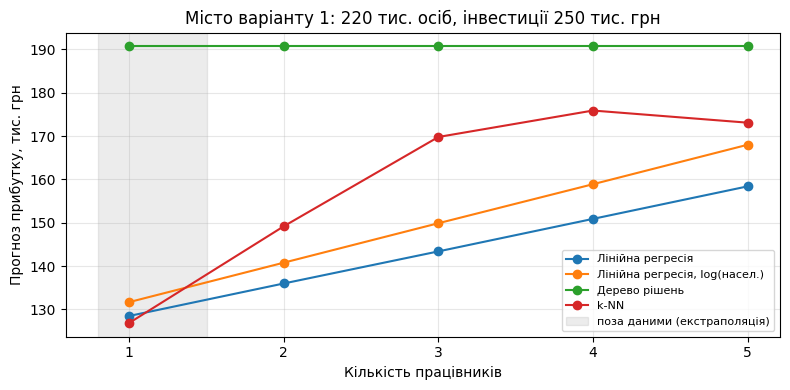

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in reg_models:
    ax.plot(res_v["employees"], res_v[name], marker="o", label=name)
ax.axvspan(0.8, 1.5, color="grey", alpha=0.15, label="поза даними (екстраполяція)")
ax.set_xlabel("Кількість працівників"); ax.set_ylabel("Прогноз прибутку, тис. грн")
ax.set_title("Місто варіанту 1: 220 тис. осіб, інвестиції 250 тис. грн")
ax.set_xticks(range(1, 6)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 1г, 1д. Вибір міст України
Населення — орієнтовна оцінка Держстату на 01.01.2022 (довоєнна; фактична чисельність змінилась через війну).
Для кожного міста перебираємо інвестиції 250–796 тис. грн (крок 50) і 2–6 працівників (діапазон навчальних даних) та обираємо:
* для 1г — комбінацію з **максимальним прогнозом прибутку**;
* для 1д — комбінацію з **мінімальним строком окупності**.

Прогноз позначається як **екстраполяція**, якщо населення > 729 тис. (найбільше місто у вибірці — Львів).

In [14]:
ua = pd.DataFrame([
    ("Київ", 2952), ("Харків", 1421), ("Одеса", 1010), ("Дніпро", 969), ("Львів", 717),
    ("Запоріжжя", 710), ("Кривий Ріг", 604), ("Миколаїв", 470), ("Вінниця", 370),
    ("Чернігів", 283), ("Полтава", 280), ("Хмельницький", 274), ("Черкаси", 270),
    ("Чернівці", 264), ("Житомир", 262), ("Суми", 257), ("Рівне", 244),
    ("Івано-Франківськ", 238), ("Тернопіль", 225), ("Кропивницький", 223),
    ("Кременчук", 215), ("Луцьк", 214), ("Біла Церква", 207), ("Ужгород", 115),
    ("Бровари", 110), ("Кам'янець-Подільський", 99), ("Мукачево", 86), ("Умань", 82),
], columns=["city", "population"])
# Безпекова ситуація — фактор поза моделлю: міста, що регулярно зазнають обстрілів / близькі до фронту
RISK = {"Харків", "Запоріжжя", "Дніпро", "Кривий Ріг", "Миколаїв", "Одеса", "Суми", "Чернігів"}

grid_inv = np.r_[np.arange(250, 751, 50), 796]   # 250…796 — діапазон інвестицій у даних
grid_emp = np.arange(2, 7)                        # 2…6 — діапазон працівників у даних
POP_MAX = X["population"].max()

def scan(city, pop):
    g = pd.DataFrame([(pop, i, e) for i in grid_inv for e in grid_emp], columns=FEATS)
    g["profit"] = best_reg.predict(g[FEATS])
    g["payback"] = np.where(g["profit"] > 0, g["investment"] / g["profit"], np.inf)
    g["lin_profit"] = lin_full.predict(g[FEATS])
    g["city"] = city
    return g

allg = pd.concat([scan(c, p) for c, p in ua.values], ignore_index=True)
allg["Екстраполяція"] = np.where(allg["population"] > POP_MAX, "так", "ні")
allg["Безпековий ризик"] = np.where(allg["city"].isin(RISK), "високий", "помірний")

def fmt(t):
    t = t.copy()
    t["ROI, %"] = (t["profit"] / t["investment"] * 100).round(1)
    return t[["city", "population", "investment", "employees", "profit", "lin_profit",
              "payback", "ROI, %", "Екстраполяція", "Безпековий ризик"]].round(2).rename(columns={
        "city": "Місто", "population": "Населення", "investment": "Інвестиції",
        "employees": "Працівників", "profit": "Прибуток (log-модель)",
        "lin_profit": "Прибуток (лінійна)", "payback": "Окупність, р."})

# 1г — максимальний прибуток у кожному місті
max_profit = allg.loc[allg.groupby("city")["profit"].idxmax()].sort_values("profit", ascending=False)
top_profit = fmt(max_profit.head(8))
top_profit

,Місто,Населення,Інвестиції,Працівників,Прибуток (log-модель),Прибуток (лінійна),"Окупність, р.","ROI, %",Екстраполяція,Безпековий ризик
59,Київ,2952,796,6,301.20,888.23,2.64,37.8,так,помірний
119,Харків,1421,796,6,280.20,508.41,2.84,35.2,так,високий
179,Одеса,1010,796,6,270.39,406.45,2.94,34.0,так,високий
239,Дніпро,969,796,6,269.20,396.28,2.96,33.8,так,високий
299,Львів,717,796,6,260.55,333.76,3.06,32.7,ні,помірний
359,Запоріжжя,710,796,6,260.27,332.02,3.06,32.7,ні,високий
419,Кривий Ріг,604,796,6,255.63,305.72,3.11,32.1,ні,високий
479,Миколаїв,470,796,6,248.42,272.48,3.20,31.2,ні,високий


In [15]:
# Рекомендовані: без екстраполяції і без високого безпекового ризику
ok = (max_profit["population"] <= POP_MAX) & ~max_profit["city"].isin(RISK)
top_profit_in = fmt(max_profit[ok].head(5))
top_profit_in

,Місто,Населення,Інвестиції,Працівників,Прибуток (log-модель),Прибуток (лінійна),"Окупність, р.","ROI, %",Екстраполяція,Безпековий ризик
299,Львів,717,796,6,260.55,333.76,3.06,32.7,ні,помірний
539,Вінниця,370,796,6,241.55,247.67,3.30,30.3,ні,помірний
659,Полтава,280,796,6,233.55,225.34,3.41,29.3,ні,помірний
719,Хмельницький,274,796,6,232.92,223.86,3.42,29.3,ні,помірний
779,Черкаси,270,796,6,232.50,222.86,3.42,29.2,ні,помірний


In [16]:
# 1д — найшвидша окупність у кожному місті
min_pb = allg.loc[allg.groupby("city")["payback"].idxmin()].sort_values("payback")
top_payback = fmt(min_pb.head(8))
ok2 = (min_pb["population"] <= POP_MAX) & ~min_pb["city"].isin(RISK)
top_payback_in = fmt(min_pb[ok2].head(5))
display(top_payback_in)
top_payback

,Місто,Населення,Інвестиції,Працівників,Прибуток (log-модель),Прибуток (лінійна),"Окупність, р.","ROI, %",Екстраполяція,Безпековий ризик
244,Львів,717,250,6,210.99,289.18,1.18,84.4,ні,помірний
484,Вінниця,370,250,6,191.99,203.10,1.30,76.8,ні,помірний
604,Полтава,280,250,6,183.98,180.77,1.36,73.6,ні,помірний
664,Хмельницький,274,250,6,183.36,179.28,1.36,73.3,ні,помірний
724,Черкаси,270,250,6,182.94,178.29,1.37,73.2,ні,помірний


,Місто,Населення,Інвестиції,Працівників,Прибуток (log-модель),Прибуток (лінійна),"Окупність, р.","ROI, %",Екстраполяція,Безпековий ризик
4,Київ,2952,250,6,251.63,843.66,0.99,100.7,так,помірний
64,Харків,1421,250,6,230.63,463.84,1.08,92.3,так,високий
124,Одеса,1010,250,6,220.83,361.87,1.13,88.3,так,високий
184,Дніпро,969,250,6,219.64,351.70,1.14,87.9,так,високий
244,Львів,717,250,6,210.99,289.18,1.18,84.4,ні,помірний
304,Запоріжжя,710,250,6,210.70,287.45,1.19,84.3,ні,високий
364,Кривий Ріг,604,250,6,206.06,261.15,1.21,82.4,ні,високий
424,Миколаїв,470,250,6,198.86,227.90,1.26,79.5,ні,високий


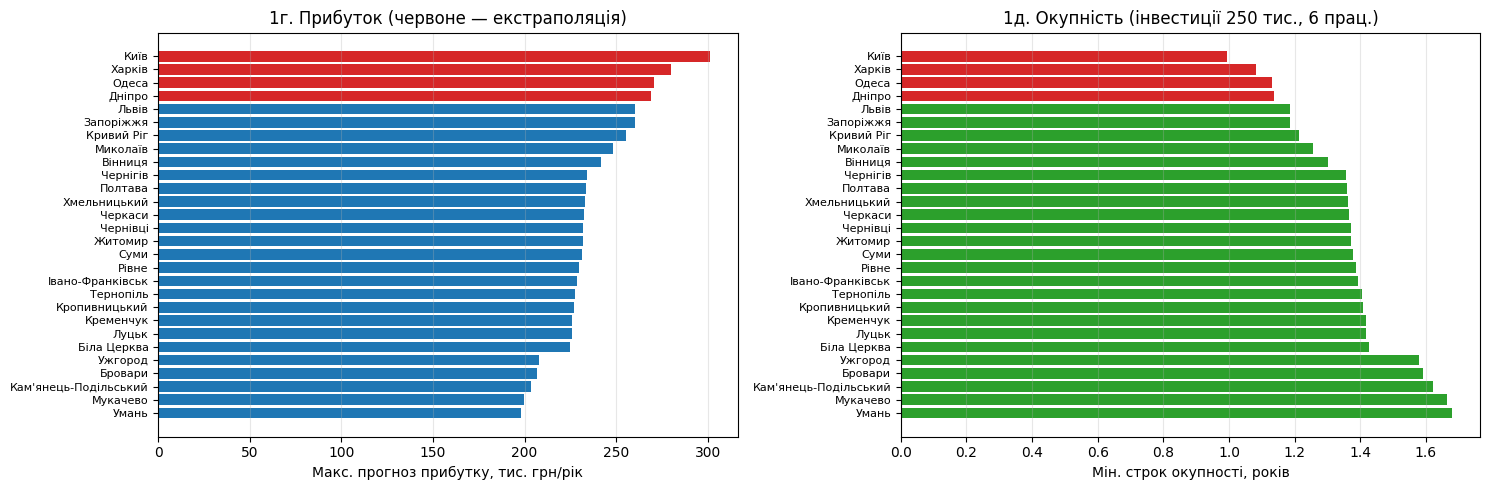

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
mp = max_profit.sort_values("profit")
cols = np.where(mp["Екстраполяція"] == "так", "#d62728", "#1f77b4")
ax[0].barh(mp["city"], mp["profit"], color=cols)
ax[0].set_xlabel("Макс. прогноз прибутку, тис. грн/рік"); ax[0].set_title("1г. Прибуток (червоне — екстраполяція)")
pb = min_pb.sort_values("payback", ascending=False)
ax[1].barh(pb["city"], pb["payback"], color=np.where(pb["Екстраполяція"] == "так", "#d62728", "#2ca02c"))
ax[1].set_xlabel("Мін. строк окупності, років"); ax[1].set_title("1д. Окупність (інвестиції 250 тис., 6 прац.)")
for a in ax: a.grid(axis="x", alpha=0.3); a.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

**Висновки 1г–1д.**
* Найбільший прогноз прибутку дають найбільші міста — Київ, Харків, Одеса, Дніпро, — але їх населення (0,97–2,95 млн)
  **поза діапазоном** навчальних даних (≤ 729 тис.). Це **екстраполяція**: лінійна модель для Києва дає 888 тис. грн, а
  log-модель — 301 тис. грн; розбіжність утричі показує, що такому прогнозу довіряти не можна.
* **1г (максимальний прибуток)**, без екстраполяції й без високого безпекового ризику: **Львів** (~261 тис. грн/рік),
  **Вінниця** (~242), **Полтава** (~234) — при інвестиціях 796 тис. грн і 6 працівниках.
* **1д (найшвидша окупність)**: ті самі **Львів** (1,18 р.), **Вінниця** (1,30 р.), **Полтава** (1,36 р.), але при **мінімальних**
  інвестиціях 250 тис. грн і 6 працівниках. Кожні додаткові 100 тис. грн інвестицій дають лише +9 тис. грн прибутку на рік,
  тому мінімальні інвестиції окуповуються найшвидше.
* Хмельницький і Черкаси відстають від Полтави лише на ~1 тис. грн — у межах похибки моделі (MAE ≈ 25 тис. грн), тож це рівноцінні резервні варіанти.

## Задача 2. Класифікація: чи окупиться магазин за 3 роки
### 2а. Цільова змінна

In [18]:
N_YEARS = 3
df["payback"] = np.where(df["profit"] > 0, df["investment"] / df["profit"], np.inf)
df["success"] = (df["payback"] <= N_YEARS).astype(int)   # збиткові -> inf -> 0
print(df["success"].value_counts().rename({0: "неуспішний (0)", 1: "успішний (1)"}))
print("\nЧастки класів:\n", df["success"].value_counts(normalize=True).round(3), sep="")
print("\nЧастка успішних за форматами:\n", df.groupby("format")["success"].mean().round(2), sep="")

success
неуспішний (0)    59
успішний (1)      20
Name: count, dtype: int64

Частки класів:
success
0    0.747
1    0.253
Name: proportion, dtype: float64

Частка успішних за форматами:
format
ТЦ              0.19
вулиця          0.26
пункт видачі    0.35
Name: success, dtype: float64


Класи незбалансовані: успішних лише ≈25 %. Тому accuracy недостатня — дивимось на precision, recall, F1 і матрицю плутанини,
а для розбиття та крос-валідації використовуємо стратифікацію.

### 2б. Логістична регресія та дерево рішень
**Вибір ознак:** `population`, `investment`, `employees`, `format` — це характеристики, **відомі до відкриття** магазину.
Виручка, прибуток, середній чек, частка онлайн і рейтинг стають відомі лише після роботи магазину (витік цільової змінної),
тому їх не беремо. Формат додаємо, бо частка успішних сильно відрізняється між форматами (пункти видачі окуповуються частіше).
Логістичній регресії потрібне масштабування (StandardScaler) і One-Hot для формату; дереву масштабування не потрібне.

In [19]:
CF_NUM = ["population", "investment", "employees"]
CF = CF_NUM + ["format"]
Xc, yc = df[CF], df["success"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.3,
                                                        stratify=yc, random_state=RS)

pre_scaled = make_column_transformer((StandardScaler(), CF_NUM),
                                     (OneHotEncoder(handle_unknown="ignore"), ["format"]))
pre_tree = make_column_transformer(("passthrough", CF_NUM),
                                   (OneHotEncoder(handle_unknown="ignore"), ["format"]))

logreg = make_pipeline(pre_scaled, LogisticRegression(max_iter=1000))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
grid_ct = GridSearchCV(make_pipeline(pre_tree, DecisionTreeClassifier(random_state=RS)),
                       {"decisiontreeclassifier__max_depth": [2, 3, 4],
                        "decisiontreeclassifier__min_samples_leaf": [2, 3, 5]},
                       cv=skf, scoring="f1").fit(Xc_train, yc_train)
tree_clf = grid_ct.best_estimator_
print("Дерево (глибина ≤ 4):", grid_ct.best_params_)
logreg.fit(Xc_train, yc_train)

Дерево (глибина ≤ 4): {'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 2}


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['population', 'investment',
                                                   'employees']),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['format'])])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

### 2в. Метрики, матриці плутанини, stratified k-fold

In [20]:
CLF_SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
clf_models = {"Логістична регресія": logreg, "Дерево рішень": tree_clf}
rows = []
for name, m in clf_models.items():
    p = m.predict(Xc_test); pr = m.predict_proba(Xc_test)[:, 1]
    print(f"===== {name} (тест) =====")
    print(classification_report(yc_test, p, target_names=["неуспішний", "успішний"], zero_division=0))
    cvr = cross_validate(m, Xc, yc, cv=skf, scoring=CLF_SCORING)
    rows.append({"Модель": name,
                 "Accuracy тест": accuracy_score(yc_test, p),
                 "Precision тест": precision_score(yc_test, p, zero_division=0),
                 "Recall тест": recall_score(yc_test, p),
                 "F1 тест": f1_score(yc_test, p),
                 "ROC-AUC тест": roc_auc_score(yc_test, pr),
                 **{f"{k.capitalize() if k!='roc_auc' else 'ROC-AUC'} CV": cvr[f"test_{k}"].mean()
                    for k in CLF_SCORING}})
clf_table = pd.DataFrame(rows).set_index("Модель").round(3)
clf_table

===== Логістична регресія (тест) =====
              precision    recall  f1-score   support

  неуспішний       0.86      1.00      0.92        18
    успішний       1.00      0.50      0.67         6

    accuracy                           0.88        24
   macro avg       0.93      0.75      0.79        24
weighted avg       0.89      0.88      0.86        24

===== Дерево рішень (тест) =====
              precision    recall  f1-score   support

  неуспішний       0.86      1.00      0.92        18
    успішний       1.00      0.50      0.67         6

    accuracy                           0.88        24
   macro avg       0.93      0.75      0.79        24
weighted avg       0.89      0.88      0.86        24



,Accuracy тест,Precision тест,Recall тест,F1 тест,ROC-AUC тест,Accuracy CV,Precision CV,Recall CV,F1 CV,ROC-AUC CV
Модель,,,,,,,,,,
Логістична регресія,0.875,1.0,0.5,0.667,0.972,0.872,0.853,0.70,0.731,0.924
Дерево рішень,0.875,1.0,0.5,0.667,0.741,0.823,0.683,0.55,0.602,0.792


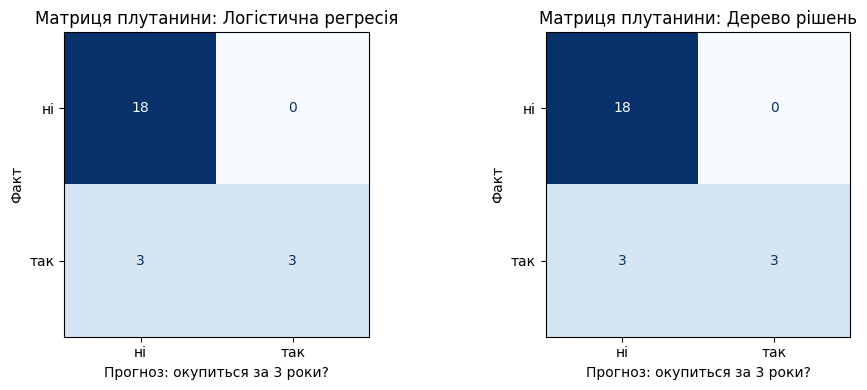

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, clf_models.items()):
    ConfusionMatrixDisplay(confusion_matrix(yc_test, m.predict(Xc_test)),
                           display_labels=["ні", "так"]).plot(cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"Матриця плутанини: {name}")
    a.set_xlabel("Прогноз: окупиться за 3 роки?"); a.set_ylabel("Факт")
plt.tight_layout(); plt.show()

**Яка метрика важливіша.** Помилка «модель сказала *так*, а магазин не окупився» (FP) означає вкладені й неповернені
сотні тисяч гривень; помилка «сказала *ні*, а магазин окупився б» (FN) — лише втрачену можливість. Тому для рішення
«відкривати магазин» головна метрика — **precision класу «успішний»**, а F1 — допоміжна, щоб модель не стала надто обережною.

### 2г. Візуалізація дерева рішень і правила мовою бізнесу

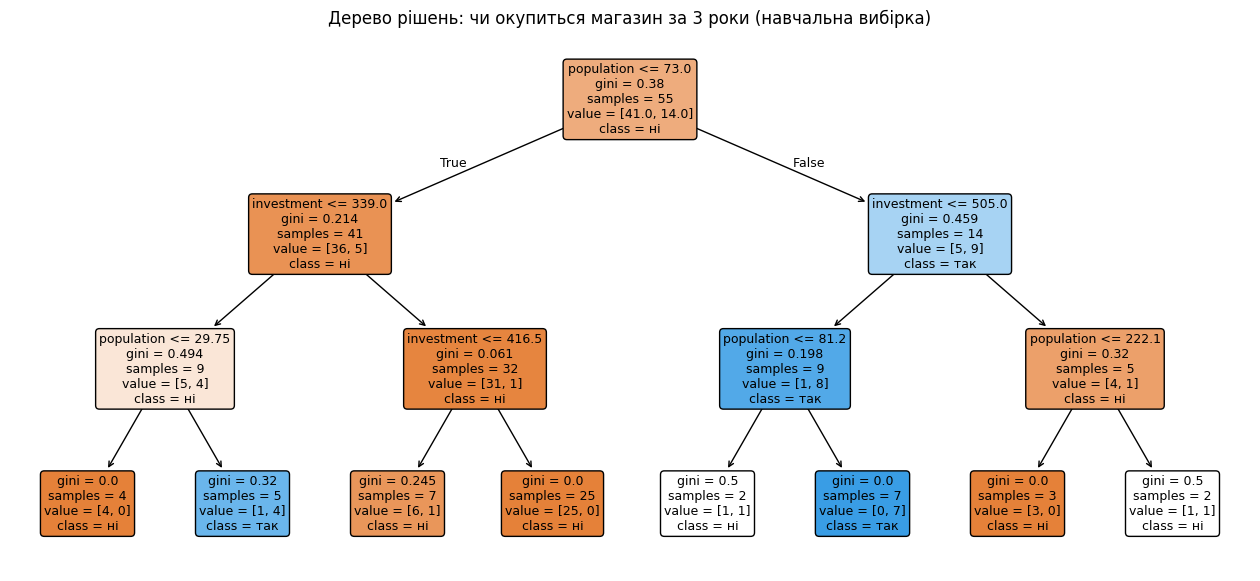

|--- population <= 73.00
|   |--- investment <= 339.00
|   |   |--- population <= 29.75
|   |   |   |--- weights: [4.00, 0.00] class: 0
|   |   |--- population >  29.75
|   |   |   |--- weights: [1.00, 4.00] class: 1
|   |--- investment >  339.00
|   |   |--- investment <= 416.50
|   |   |   |--- weights: [6.00, 1.00] class: 0
|   |   |--- investment >  416.50
|   |   |   |--- weights: [25.00, 0.00] class: 0
|--- population >  73.00
|   |--- investment <= 505.00
|   |   |--- population <= 81.20
|   |   |   |--- weights: [1.00, 1.00] class: 0
|   |   |--- population >  81.20
|   |   |   |--- weights: [0.00, 7.00] class: 1
|   |--- investment >  505.00
|   |   |--- population <= 222.10
|   |   |   |--- weights: [3.00, 0.00] class: 0
|   |   |--- population >  222.10
|   |   |   |--- weights: [1.00, 1.00] class: 0



In [22]:
tree_feat = CF_NUM + list(tree_clf[0].named_transformers_["onehotencoder"].get_feature_names_out(["format"]))
fig = plt.figure(figsize=(16, 7))
plot_tree(tree_clf[-1], feature_names=tree_feat, class_names=["ні", "так"],
          filled=True, rounded=True, fontsize=9, impurity=True, proportion=False)
plt.title("Дерево рішень: чи окупиться магазин за 3 роки (навчальна вибірка)")
plt.show()
print(export_text(tree_clf[-1], feature_names=tree_feat, show_weights=True))

In [23]:
# Перевірка правил дерева на ВСІХ 79 магазинах: частка успішних у кожному листку
leaf = tree_clf[-1].apply(tree_clf[0].transform(Xc))
rules = df.assign(leaf=leaf).groupby("leaf").agg(
    магазинів=("success", "size"), успішних=("success", "sum"),
    частка=("success", "mean"), насел_мін=("population", "min"), насел_макс=("population", "max"),
    інвест_мін=("investment", "min"), інвест_макс=("investment", "max")).round(2)
rules

,магазинів,успішних,частка,насел_мін,насел_макс,інвест_мін,інвест_макс
leaf,,,,,,,
3,7,2,0.29,14.2,29.4,250,334
4,5,4,0.80,30.1,61.4,263,338
6,12,2,0.17,13.2,69.1,340,413
7,35,0,0.00,13.2,67.9,420,793
10,2,1,0.50,76.9,76.9,423,470
11,10,10,1.00,85.5,245.3,281,460
13,4,0,0.00,85.5,217.1,580,735
14,4,1,0.25,227.1,729.1,540,796


### 2д. Застосування класифікаторів до міста варіанту 1 і порівняння з регресією
Формат у варіанті не задано, тому рахуємо для кожного формату.

In [24]:
# використовуємо ті самі моделі, що оцінені вище (навчені на train), щоб правила дерева з 2г збігались із прогнозом
rows = []
for fmt_ in ["ТЦ", "вулиця", "пункт видачі"]:
    for e in range(1, 6):
        z = pd.DataFrame([{"population": 220, "investment": 250, "employees": e, "format": fmt_}])
        rp = best_reg.predict(z[FEATS])[0]
        rows.append({"Формат": fmt_, "Працівників": e,
                     "P(успіх) логіст.": logreg.predict_proba(z)[0, 1],
                     "Логіст.": "так" if logreg.predict(z)[0] else "ні",
                     "P(успіх) дерево": tree_clf.predict_proba(z)[0, 1],
                     "Дерево": "так" if tree_clf.predict(z)[0] else "ні",
                     "Регресія: прибуток": rp, "Регресія: окупність": 250 / rp,
                     "Регресія": "так" if 250 / rp <= N_YEARS else "ні"})
cmp_v = pd.DataFrame(rows).round(2)
cmp_v

,Формат,Працівників,P(успіх) логіст.,Логіст.,P(успіх) дерево,Дерево,Регресія: прибуток,Регресія: окупність,Регресія
0,ТЦ,1,0.83,так,1.0,так,131.74,1.90,так
1,ТЦ,2,0.84,так,1.0,так,140.81,1.78,так
2,ТЦ,3,0.86,так,1.0,так,149.87,1.67,так
3,ТЦ,4,0.87,так,1.0,так,158.93,1.57,так
4,ТЦ,5,0.89,так,1.0,так,167.99,1.49,так
5,вулиця,1,0.87,так,1.0,так,131.74,1.90,так
6,вулиця,2,0.88,так,1.0,так,140.81,1.78,так
7,вулиця,3,0.89,так,1.0,так,149.87,1.67,так
8,вулиця,4,0.91,так,1.0,так,158.93,1.57,так
9,вулиця,5,0.92,так,1.0,так,167.99,1.49,так


**Висновок 2д.** Для міста варіанту 1 (220 тис. осіб, 250 тис. грн) обидва класифікатори і регресія дають однаковий висновок:
**магазин окупиться за 3 роки** при будь-якій кількості працівників 1–5 і будь-якому форматі. Регресія прогнозує окупність 1,5–1,9 року,
логістична регресія — імовірність успіху 0,83–0,94, дерево потрапляє в листок «населення > 81 тис. і інвестиції ≤ 505 тис.», де 10 із 10 магазинів мережі окупились.

## Зведена порівняльна таблиця моделей

In [25]:
print("РЕГРЕСІЯ (ціль — прибуток, тис. грн)")
print(reg_table.to_string())
print("\nКЛАСИФІКАЦІЯ (ціль — окупність ≤ 3 роки)")
print(clf_table.to_string())

РЕГРЕСІЯ (ціль — прибуток, тис. грн)
                               MAE тест  RMSE тест  R2 тест  MAE CV  RMSE CV  R2 CV  R2 CV std
Модель                                                                                        
Лінійна регресія                 26.355     39.171    0.214  28.291   35.586  0.356      0.154
Лінійна регресія, log(насел.)    20.968     26.902    0.629  25.468   30.947  0.496      0.199
Дерево рішень                    33.396     42.494    0.075  34.987   41.656  0.104      0.279
k-NN                             24.124     30.296    0.530  29.193   36.403  0.309      0.194

КЛАСИФІКАЦІЯ (ціль — окупність ≤ 3 роки)
                     Accuracy тест  Precision тест  Recall тест  F1 тест  ROC-AUC тест  Accuracy CV  Precision CV  Recall CV  F1 CV  ROC-AUC CV
Модель                                                                                                                                         
Логістична регресія          0.875             1.0          0.5

## Задача 3 (додаткова). Класифікація продукції на сортувальній лінії
Зразок варіанту 1: вага 250 г, діаметр 4 см, колір **білий**, товщина 3, матеріал **дерево**.

In [26]:
dt = pd.read_excel("DataTypes.xlsx")
dt.columns = ["n", "diameter", "color", "weight", "thickness", "material", "type"]
print(dt.groupby("type").agg(n=("n", "size"), вага=("weight", "mean"), діаметр=("diameter", "mean"),
                             товщина=("thickness", "mean"),
                             матеріал=("material", lambda s: ", ".join(sorted(set(s)))),
                             колір=("color", lambda s: ", ".join(sorted(set(s))))).round(1).to_string())

NUM3, CAT3 = ["weight", "diameter", "thickness"], ["color", "material"]
X3, y3 = dt[NUM3 + CAT3], dt["type"]
pre3 = make_column_transformer((StandardScaler(), NUM3),
                               (OneHotEncoder(handle_unknown="ignore"), CAT3))   # «білий» невідомий -> нулі
sample = pd.DataFrame([{"weight": 250, "diameter": 4, "thickness": 3, "color": "білий", "material": "дерево"}])

knn3 = GridSearchCV(make_pipeline(pre3, KNeighborsClassifier()),
                    {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7]},
                    cv=StratifiedKFold(3, shuffle=True, random_state=RS)).fit(X3, y3)
svm3 = make_pipeline(pre3, SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RS)).fit(X3, y3)
print("\nk-NN: найкраще k =", knn3.best_params_, " CV accuracy =", round(knn3.best_score_, 3))
print("SVM : CV accuracy =", round(cross_validate(svm3, X3, y3,
      cv=StratifiedKFold(3, shuffle=True, random_state=RS))["test_score"].mean(), 3))
print("\nПрогноз для зразка: k-NN ->", knn3.predict(sample)[0], " | SVM ->", svm3.predict(sample)[0])
print("Ймовірності SVM по типах 1/2/3:", svm3.predict_proba(sample).round(2))

# найближчі сусіди зразка
Zs = knn3.best_estimator_[0].transform(sample); Z3 = knn3.best_estimator_[0].transform(X3)
d = np.sqrt(((Z3 - Zs) ** 2).sum(axis=1))
print("\n5 найближчих зразків:")
print(dt.assign(відстань=d.round(2)).nsmallest(5, "відстань").to_string(index=False))

      n   вага  діаметр  товщина матеріал                               колір
type                                                                         
1     8   71.5      6.5      2.0  пластик        жовтий, фіолетовий, червоний
2     7  102.9      5.0      2.7   дерево  жовтий, зелений, рожевий, червоний
3     5  213.0      3.0      1.0    метал                             зелений

k-NN: найкраще k = {'kneighborsclassifier__n_neighbors': 1}  CV accuracy = 0.952
SVM : CV accuracy = 0.952

Прогноз для зразка: k-NN -> 2  | SVM -> 2
Ймовірності SVM по типах 1/2/3: [[0.1  0.75 0.15]]

5 найближчих зразків:
 n  diameter    color  weight  thickness material  type  відстань
14         6   жовтий     145          3   дерево     2      1.91
18         8  рожевий     167          3   дерево     2      2.23
13         7 червоний     122          3   дерево     2      2.34
 9         5 червоний      89          3   дерево     2      2.42
 8         4 червоний      76          3   дерево     2

Товщина 30 мм: k-NN -> 2  | SVM -> 2


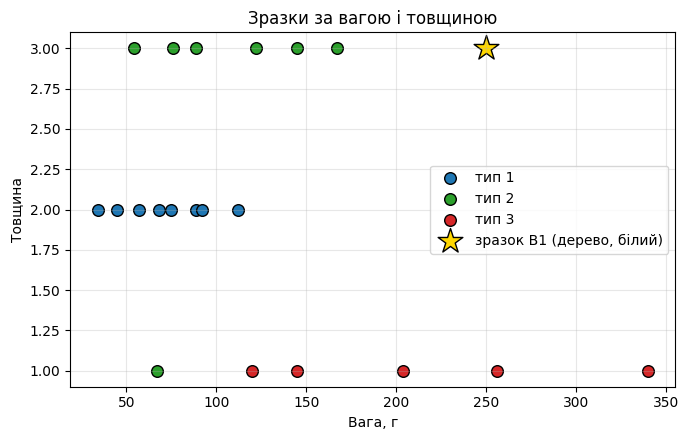

In [27]:
# Чутливість: що, якщо товщину 3 см переводити в мм (30 мм)?
s2 = sample.assign(thickness=30)
print("Товщина 30 мм: k-NN ->", knn3.predict(s2)[0], " | SVM ->", svm3.predict(s2)[0])

fig, ax = plt.subplots(figsize=(7, 4.5))
for t, c in zip([1, 2, 3], ["#1f77b4", "#2ca02c", "#d62728"]):
    sub = dt[dt["type"] == t]
    ax.scatter(sub["weight"], sub["thickness"], s=70, c=c, label=f"тип {t}", edgecolor="k")
ax.scatter(250, 3, marker="*", s=350, c="gold", edgecolor="k", label="зразок В1 (дерево, білий)")
ax.set_xlabel("Вага, г"); ax.set_ylabel("Товщина"); ax.set_title("Зразки за вагою і товщиною")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Висновок задачі 3.** Обидва методи відносять зразок до **типу 2**. Вирішальна ознака — матеріал «дерево»: у навчальних даних
всі дерев'яні зразки мають тип 2, а 5 найближчих сусідів зразка — дерев'яні типу 2. Вага 250 г більше схожа на металеві
зразки типу 3 (середня вага 213 г), тому SVM дає типу 3 імовірність 0,15, а не нуль. Колір «білий» у навчальних даних відсутній —
One-Hot кодує його нулями, тому колір на рішення не впливає. Розбіжностей між методами немає; результат не змінюється і при товщині 30 мм.